# Portfolio MF-DCCA Robustness & Publication-Readiness Tests

Companion to `portfolio_mfdcca_var.ipynb`. Self-contained — loads data and
re-defines all helper functions so it can run independently.

**Sections**

12. Surrogate / bootstrap hypothesis tests for MDR, Δh, ρ_DCCA rankings
13. Monte Carlo stability — 200 random 7-asset draws from 50-ticker universe
14. BTC / equity calendar alignment sensitivity
15. MF-DCCA vs. linear rolling-correlation retention — dedicated analysis
16. Rolling MF-DCCA formal event study with named stress episodes


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import os
import warnings
from scipy.stats import kendalltau
from itertools import combinations

matplotlib.rcParams["figure.dpi"] = 110
warnings.filterwarnings('ignore', category=RuntimeWarning)

# ------------------------------------------------------------------
# MF-DFA / MF-DCCA core (same as portfolio_mfdcca_var.ipynb)
# ------------------------------------------------------------------
def profile(x):
    return np.cumsum(np.asarray(x) - np.mean(x))

def _local_residuals(Y, s, order=1, sign_filter=None):
    N = len(Y); Ns = N // s; t = np.arange(s)
    out = []
    for v in range(Ns):
        seg = Y[v*s:(v+1)*s]
        c = np.polyfit(t, seg, order)
        if sign_filter == "+" and c[-2] < 0: continue
        if sign_filter == "-" and c[-2] >= 0: continue
        out.append(np.mean((seg - np.polyval(c, t)) ** 2))
    for v in range(Ns):
        seg = Y[N-(v+1)*s:N-v*s]
        c = np.polyfit(t, seg, order)
        if sign_filter == "+" and c[-2] < 0: continue
        if sign_filter == "-" and c[-2] >= 0: continue
        out.append(np.mean((seg - np.polyval(c, t)) ** 2))
    return np.array(out)

def mfdfa(x, q_list, scales, order=1, sign_filter=None):
    Y = profile(x)
    q_list = np.asarray(q_list, dtype=float)
    Fq = np.zeros((len(q_list), len(scales)))
    for si, s in enumerate(scales):
        F2 = _local_residuals(Y, s, order, sign_filter)
        F2 = F2[F2 > 1e-14]
        for qi, q in enumerate(q_list):
            if abs(q) < 1e-8:
                Fq[qi, si] = np.exp(0.5*np.mean(np.log(F2)))
            else:
                Fq[qi, si] = np.mean(F2**(q/2.0))**(1.0/q)
    hq = np.array([np.polyfit(np.log(scales), np.log(Fq[qi]), 1)[0]
                    for qi in range(len(q_list))])
    return Fq, hq

def multifractal_spectrum(q_list, hq):
    q = np.asarray(q_list, dtype=float)
    tau = q*hq - 1
    alpha = np.gradient(tau, q)
    f = q*alpha - tau
    return tau, alpha, f

def dcca_rho(x, y, s, order=1):
    X, Y2 = profile(x), profile(y)
    N = len(X); Ns = N // s; t = np.arange(s)
    Fxx = Fyy = Fxy = 0.0
    for v in range(Ns):
        xs, ys = X[v*s:(v+1)*s], Y2[v*s:(v+1)*s]
        cx = np.polyval(np.polyfit(t, xs, order), t)
        cy = np.polyval(np.polyfit(t, ys, order), t)
        rx, ry = xs-cx, ys-cy
        Fxx += np.mean(rx**2); Fyy += np.mean(ry**2); Fxy += np.mean(rx*ry)
    Fxx, Fyy, Fxy = Fxx/Ns, Fyy/Ns, Fxy/Ns
    return Fxy / np.sqrt(Fxx*Fyy)

def shuffle_surrogate(x, rng=None):
    """Randomly shuffle returns — destroys temporal correlations / multifractality."""
    if rng is None:
        rng = np.random.default_rng()
    s = x.copy()
    rng.shuffle(s)
    return s

def hill_estimator(losses, k):
    x = np.sort(losses)[::-1][:k+1]
    logs = np.log(x[:-1] / x[-1])
    return k / np.sum(logs)

print("Core MF-DFA / MF-DCCA / surrogate / Hill functions loaded.")


Core MF-DFA / MF-DCCA / surrogate / Hill functions loaded.


## Data Loading

Same ticker universe and `stock_csv_data/` convention as `portfolio_mfdcca_var.ipynb`.
Loads both the 7-asset portfolio **and** the full 50-ticker universe for Monte Carlo draws.


In [2]:
TICKERS = [
    # US Large Cap Tech
    "AAPL", "MSFT", "GOOG", "AMZN", "NVDA",
    "META", "TSLA", "NFLX", "AMD", "INTC",
    # US Financials
    "JPM", "BAC", "GS", "MS", "WFC",
    "BLK", "C", "AXP", "V", "MA",
    # US Healthcare & Consumer
    "JNJ", "PFE", "UNH", "MRK", "ABBV",
    "PG", "KO", "PEP", "WMT", "COST",
    # US Energy & Industrials
    "XOM", "CVX", "COP", "BA", "CAT",
    "GE", "HON", "LMT", "RTX", "UPS",
    # Commodities & Crypto
    "GC=F", "SI=F", "CL=F", "BTC-USD", "ETH-USD",
    # International ETFs
    "EWJ", "EWZ", "FXI", "EWG", "EWU",
]

START, END = "2010-01-01", "2026-04-11"
OUT_DIR = "stock_csv_data"
os.makedirs(OUT_DIR, exist_ok=True)

PORTFOLIO = ["AAPL", "JPM", "XOM", "JNJ", "GC=F", "BTC-USD", "EWJ"]
SECTOR    = {"AAPL":"Tech", "JPM":"Financials", "XOM":"Energy", "JNJ":"Healthcare",
             "GC=F":"Commodity", "BTC-USD":"Crypto", "EWJ":"Intl ETF"}

def csv_path(ticker, folder=OUT_DIR):
    return os.path.join(folder, f"{ticker.replace('=', '_')}_data.csv")

def get_prices(tickers, start=START, end=END, folder=OUT_DIR):
    series = {}
    for t in tickers:
        path = csv_path(t, folder)
        if not os.path.exists(path):
            import yfinance as yf
            print(f"Downloading {t} ...")
            data = yf.download(t, start=start, end=end, progress=False)
            if isinstance(data.columns, pd.MultiIndex):
                data.columns = data.columns.get_level_values(0)
            data.to_csv(path)
        df = pd.read_csv(path)
        df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
        df = df.dropna(subset=["Date"]).set_index("Date")
        series[t] = pd.to_numeric(df["Close"], errors="coerce")
    price_df = pd.DataFrame(series).dropna()
    return price_df

# ── Load the 7-asset portfolio ──
price_df = get_prices(PORTFOLIO)
returns  = {t: np.diff(np.log(price_df[t].values)) for t in PORTFOLIO}
dates    = price_df.index[1:]
N        = len(dates)
print(f"{len(PORTFOLIO)} assets, {N} aligned daily log-returns "
      f"({dates[0].date()} -> {dates[-1].date()}, ~{N/252:.1f} yrs)")

# ── Load full 50-ticker universe (individual prices, for Monte Carlo) ──
all_individual_prices = {}
for t in TICKERS:
    path = csv_path(t)
    if os.path.exists(path):
        df_t = pd.read_csv(path)
        df_t["Date"] = pd.to_datetime(df_t["Date"], errors="coerce")
        df_t = df_t.dropna(subset=["Date"]).set_index("Date")
        s_t = pd.to_numeric(df_t["Close"], errors="coerce").dropna()
        if len(s_t) > 500:
            all_individual_prices[t] = s_t
print(f"Loaded {len(all_individual_prices)} tickers for Monte Carlo universe "
      f"(min {min(len(s) for s in all_individual_prices.values())} – "
      f"max {max(len(s) for s in all_individual_prices.values())} days)")
available_tickers = sorted(all_individual_prices.keys())


7 assets, 2904 aligned daily log-returns (2014-09-18 -> 2026-04-10, ~11.5 yrs)


Loaded 50 tickers for Monte Carlo universe (min 3075 – max 4224 days)


## Baseline Computations (from `portfolio_mfdcca_var.ipynb`)

Reproduces the key variables (MF-DFA spectra, MDR, retention rankings, volatility)
that the robustness tests will be applied to.


In [3]:
# ── MF-DFA per component ──
q_list = np.array([-5,-3,-1,1,2,3,4,5], dtype=float)
scales = np.unique(np.geomspace(16, N//8, 16).astype(int))

spectra = {}
for name, r in returns.items():
    Fq, hq = mfdfa(r, q_list, scales)
    tau, alpha, f = multifractal_spectrum(q_list, hq)
    spectra[name] = dict(hq=hq, tau=tau, alpha=alpha, f=f, width=hq[0]-hq[-1])

for name in PORTFOLIO:
    s = spectra[name]
    print(f"{name:9s} ({SECTOR[name]:10s})  h(2)={s['hq'][q_list==2][0]:.3f}   width Δh={s['width']:.3f}")

# ── Equal-weight portfolio ──
weights  = np.ones(len(PORTFOLIO)) / len(PORTFOLIO)
port_ret = sum(w*returns[n] for w, n in zip(weights, PORTFOLIO))

# ── Portfolio MF-DFA ──
Fq_p, hq_p = mfdfa(port_ret, q_list, scales)
width_p     = hq_p[0] - hq_p[-1]
naive_width = sum(w*spectra[n]["width"] for w, n in zip(weights, PORTFOLIO))

# ── MDR ──
MDR = naive_width / width_p
print(f"\nPortfolio Δh = {width_p:.4f},  naive avg Δh = {naive_width:.4f}")
print(f"MDR = {MDR:.3f}")

# ── Volatility ──
vol   = {name: np.abs(r) for name, r in returns.items()}
vol_p = np.abs(port_ret)

# ── Pairwise MF-DCCA scales ──
s_fixed = np.unique(np.geomspace(16, N//8, 12).astype(int))

# ── Retention ranking (ρ_DCCA) ──
vol_dcca_rows = []
for name in PORTFOLIO:
    rhos = [dcca_rho(vol[name], vol_p, s) for s in s_fixed]
    vol_dcca_rows.append((name, np.mean(rhos), rhos))
vol_dcca_rows.sort(key=lambda r: -r[1])

print("\nVolatility-character retention ranking (avg ρ_DCCA):")
for rank, (name, avg_rho, _) in enumerate(vol_dcca_rows, 1):
    print(f"  {rank}. {name:9s} ({SECTOR[name]:10s})  avg ρ_DCCA = {avg_rho:.3f}")

# ── Rolling vol correlation (linear baseline) ──
ROLL_VOL_WIN = 21
roll_vol   = {name: pd.Series(vol[name]).rolling(ROLL_VOL_WIN).mean().values for name in PORTFOLIO}
roll_vol_p = pd.Series(vol_p).rolling(ROLL_VOL_WIN).mean().values

print(f"\n{'Ticker':9s}  corr(rolling {ROLL_VOL_WIN}d |r_i|, rolling |r_portfolio|)")
corr_rows = []
for name in PORTFOLIO:
    mask = ~(np.isnan(roll_vol[name]) | np.isnan(roll_vol_p))
    c = np.corrcoef(roll_vol[name][mask], roll_vol_p[mask])[0,1]
    corr_rows.append((name, c))
corr_rows.sort(key=lambda r: -r[1])
for name, c in corr_rows:
    print(f"{name:9s}  {c:.3f}")


AAPL      (Tech      )  h(2)=0.506   width Δh=0.232
JPM       (Financials)  h(2)=0.484   width Δh=0.208
XOM       (Energy    )  h(2)=0.497   width Δh=0.296
JNJ       (Healthcare)  h(2)=0.449   width Δh=0.308
GC=F      (Commodity )  h(2)=0.433   width Δh=0.241
BTC-USD   (Crypto    )  h(2)=0.566   width Δh=0.300
EWJ       (Intl ETF  )  h(2)=0.430   width Δh=0.185

Portfolio Δh = 0.2405,  naive avg Δh = 0.2530
MDR = 1.052



Volatility-character retention ranking (avg ρ_DCCA):
  1. JPM       (Financials)  avg ρ_DCCA = 0.782
  2. EWJ       (Intl ETF  )  avg ρ_DCCA = 0.733
  3. XOM       (Energy    )  avg ρ_DCCA = 0.705
  4. AAPL      (Tech      )  avg ρ_DCCA = 0.689
  5. JNJ       (Healthcare)  avg ρ_DCCA = 0.671
  6. BTC-USD   (Crypto    )  avg ρ_DCCA = 0.562
  7. GC=F      (Commodity )  avg ρ_DCCA = 0.452

Ticker     corr(rolling 21d |r_i|, rolling |r_portfolio|)
JPM        0.869
JNJ        0.818
XOM        0.790
AAPL       0.783
EWJ        0.707
BTC-USD    0.496
GC=F       0.422


## 12. Surrogate / Bootstrap Hypothesis Tests

Every key reported number — MDR, Δh (portfolio and component), ρ_DCCA retention
rankings — is tested against an iid-shuffle null. The surrogate preserves the marginal
distribution of each component but destroys all temporal structure (long-memory,
multifractality, cross-correlations).

If the observed value is outside the 95 % surrogate envelope, the signal is
**not explainable by the marginal distribution alone** — the temporal / cross-correlation
structure is doing real work.

**N_SURR = 199** (publication-grade; one-sided p-value resolution = 1/200 = 0.005).


Running 199 surrogate replications…


  surrogate 50/199


  surrogate 100/199


  surrogate 150/199


Surrogate loop complete.


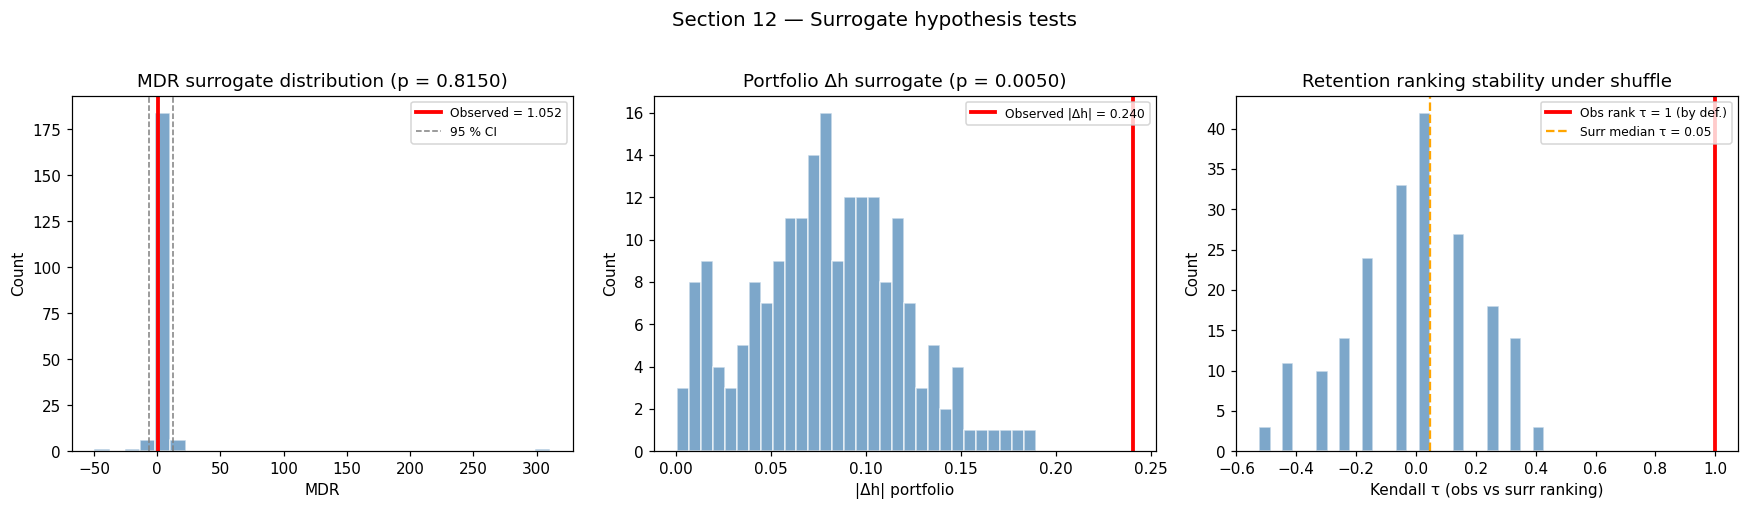


Statistic                        Observed  Surr median               95% CI    p-value
-------------------------------------------------------------------------------------
MDR                                 1.052        1.525 [-6.847, 12.691]       0.8150
Portfolio |Δh|                      0.240        0.079 [0.009, 0.157]       0.0050

Component Δh surrogate tests:
Ticker      Obs |Δh|   Surr med             95% CI        p
AAPL           0.232      0.124 [0.025, 0.207]     0.0100
JPM            0.208      0.155 [0.059, 0.227]     0.1350
XOM            0.296      0.111 [0.025, 0.183]     0.0050
JNJ            0.308      0.136 [0.037, 0.209]     0.0050
GC=F           0.241      0.137 [0.042, 0.203]     0.0150
BTC-USD        0.300      0.147 [0.057, 0.237]     0.0050
EWJ            0.185      0.104 [0.021, 0.178]     0.0200


In [4]:
# ── Section 12: Surrogate / Bootstrap Hypothesis Tests ──────────────────────

N_SURR   = 199
rng_surr = np.random.default_rng(42)

# ─── Observed values ───
obs_MDR     = MDR
obs_width_p = width_p
obs_widths  = {name: spectra[name]['width'] for name in PORTFOLIO}

# Observed retention ranking (avg ρ_DCCA across scales)
obs_retention = []
for name in PORTFOLIO:
    rhos = [dcca_rho(vol[name], vol_p, s) for s in s_fixed]
    obs_retention.append((name, np.mean(rhos)))
obs_retention.sort(key=lambda r: -r[1])
obs_rank_order = [name for name, _ in obs_retention]

# ─── Surrogate loop ───
surr_MDRs      = np.empty(N_SURR)
surr_widths_p  = np.empty(N_SURR)
surr_widths    = {name: np.empty(N_SURR) for name in PORTFOLIO}
surr_rank_taus = np.empty(N_SURR)

# Reduced scale set for DCCA inside loop (speed)
s_surr = np.unique(np.geomspace(16, N//8, 6).astype(int))

print(f"Running {N_SURR} surrogate replications…")
for rep in range(N_SURR):
    if (rep + 1) % 50 == 0:
        print(f"  surrogate {rep+1}/{N_SURR}")

    # Shuffle each component independently
    sr = {name: shuffle_surrogate(returns[name], rng_surr) for name in PORTFOLIO}

    # Portfolio
    sp = sum(w * sr[n] for w, n in zip(weights, PORTFOLIO))

    # MF-DFA per component
    s_spec = {}
    for name in PORTFOLIO:
        _, hq_s = mfdfa(sr[name], q_list, scales)
        w_s = hq_s[0] - hq_s[-1]
        s_spec[name] = w_s
        surr_widths[name][rep] = w_s

    # Portfolio MF-DFA
    _, hq_ps = mfdfa(sp, q_list, scales)
    w_ps = hq_ps[0] - hq_ps[-1]
    surr_widths_p[rep] = w_ps

    # MDR
    naive_s = sum(w * s_spec[n] for w, n in zip(weights, PORTFOLIO))
    surr_MDRs[rep] = naive_s / w_ps if abs(w_ps) > 1e-12 else np.nan

    # Retention ranking (ρ_DCCA of |surr_ret| vs |surr_port|)
    sv  = {name: np.abs(sr[name]) for name in PORTFOLIO}
    svp = np.abs(sp)
    sr_retention = []
    for name in PORTFOLIO:
        rhos = [dcca_rho(sv[name], svp, s) for s in s_surr]
        sr_retention.append((name, np.mean(rhos)))
    sr_retention.sort(key=lambda r: -r[1])
    sr_rank = [name for name, _ in sr_retention]

    obs_idx = {name: i for i, name in enumerate(obs_rank_order)}
    sr_idx  = [obs_idx[name] for name in sr_rank]
    tau_val, _ = kendalltau(range(len(PORTFOLIO)), sr_idx)
    surr_rank_taus[rep] = tau_val

print("Surrogate loop complete.")

# ─── p-values ───
def surr_pvalue(obs, dist, tail='right'):
    if tail == 'right':
        return (np.nansum(dist >= obs) + 1) / (np.sum(np.isfinite(dist)) + 1)
    return (np.nansum(dist <= obs) + 1) / (np.sum(np.isfinite(dist)) + 1)

p_MDR     = surr_pvalue(obs_MDR, surr_MDRs)
p_width_p = surr_pvalue(abs(obs_width_p), np.abs(surr_widths_p))

# ─── Plots ───
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ax = axes[0]
valid = surr_MDRs[np.isfinite(surr_MDRs)]
ax.hist(valid, bins=30, alpha=0.7, color='steelblue', edgecolor='white')
ax.axvline(obs_MDR, color='red', lw=2.5, label=f'Observed = {obs_MDR:.3f}')
ax.axvline(np.nanpercentile(valid, 2.5), color='gray', ls='--', lw=1)
ax.axvline(np.nanpercentile(valid, 97.5), color='gray', ls='--', lw=1, label='95 % CI')
ax.set_xlabel('MDR'); ax.set_ylabel('Count')
ax.set_title(f'MDR surrogate distribution (p = {p_MDR:.4f})')
ax.legend(fontsize=8)

ax = axes[1]
ax.hist(np.abs(surr_widths_p), bins=30, alpha=0.7, color='steelblue', edgecolor='white')
ax.axvline(abs(obs_width_p), color='red', lw=2.5, label=f'Observed |Δh| = {abs(obs_width_p):.3f}')
ax.set_xlabel('|Δh| portfolio'); ax.set_ylabel('Count')
ax.set_title(f'Portfolio Δh surrogate (p = {p_width_p:.4f})')
ax.legend(fontsize=8)

ax = axes[2]
v2 = surr_rank_taus[np.isfinite(surr_rank_taus)]
ax.hist(v2, bins=25, alpha=0.7, color='steelblue', edgecolor='white')
ax.axvline(1.0, color='red', lw=2.5, label='Obs rank τ = 1 (by def.)')
median_tau = np.nanmedian(v2)
ax.axvline(median_tau, color='orange', lw=1.5, ls='--', label=f'Surr median τ = {median_tau:.2f}')
ax.set_xlabel('Kendall τ (obs vs surr ranking)'); ax.set_ylabel('Count')
ax.set_title('Retention ranking stability under shuffle')
ax.legend(fontsize=8)

plt.suptitle('Section 12 — Surrogate hypothesis tests', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

# ─── Summary table ───
ci_fn = lambda d: (np.nanpercentile(d, 2.5), np.nanpercentile(d, 97.5))

print(f"\n{'Statistic':30s} {'Observed':>10s} {'Surr median':>12s} {'95% CI':>20s} {'p-value':>10s}")
print("-" * 85)
lo, hi = ci_fn(surr_MDRs)
print(f"{'MDR':30s} {obs_MDR:10.3f} {np.nanmedian(surr_MDRs):12.3f} [{lo:.3f}, {hi:.3f}]   {p_MDR:10.4f}")
lo, hi = ci_fn(np.abs(surr_widths_p))
print(f"{'Portfolio |Δh|':30s} {abs(obs_width_p):10.3f} {np.nanmedian(np.abs(surr_widths_p)):12.3f} [{lo:.3f}, {hi:.3f}]   {p_width_p:10.4f}")

print(f"\nComponent Δh surrogate tests:")
print(f"{'Ticker':9s} {'Obs |Δh|':>10s} {'Surr med':>10s} {'95% CI':>18s} {'p':>8s}")
for name in PORTFOLIO:
    ow = abs(obs_widths[name])
    sw = np.abs(surr_widths[name])
    p  = surr_pvalue(ow, sw)
    lo, hi = ci_fn(sw)
    print(f"{name:9s} {ow:10.3f} {np.nanmedian(sw):10.3f} [{lo:.3f}, {hi:.3f}]   {p:8.4f}")


## 13. Monte Carlo Stability — Random 7-Asset Draws

Shows that MDR, Δh, and the retention ranking are **stable properties of the method**,
not artefacts of one hand-picked portfolio. We draw 200 random 7-asset subsets from the
full 50-ticker universe, re-run the core pipeline on each, and report distributions.


Running 200 random 7-asset draws…


  draw 50/200


  draw 100/200


  draw 150/200


  draw 200/200


Completed 200 valid draws (of 200 attempted).


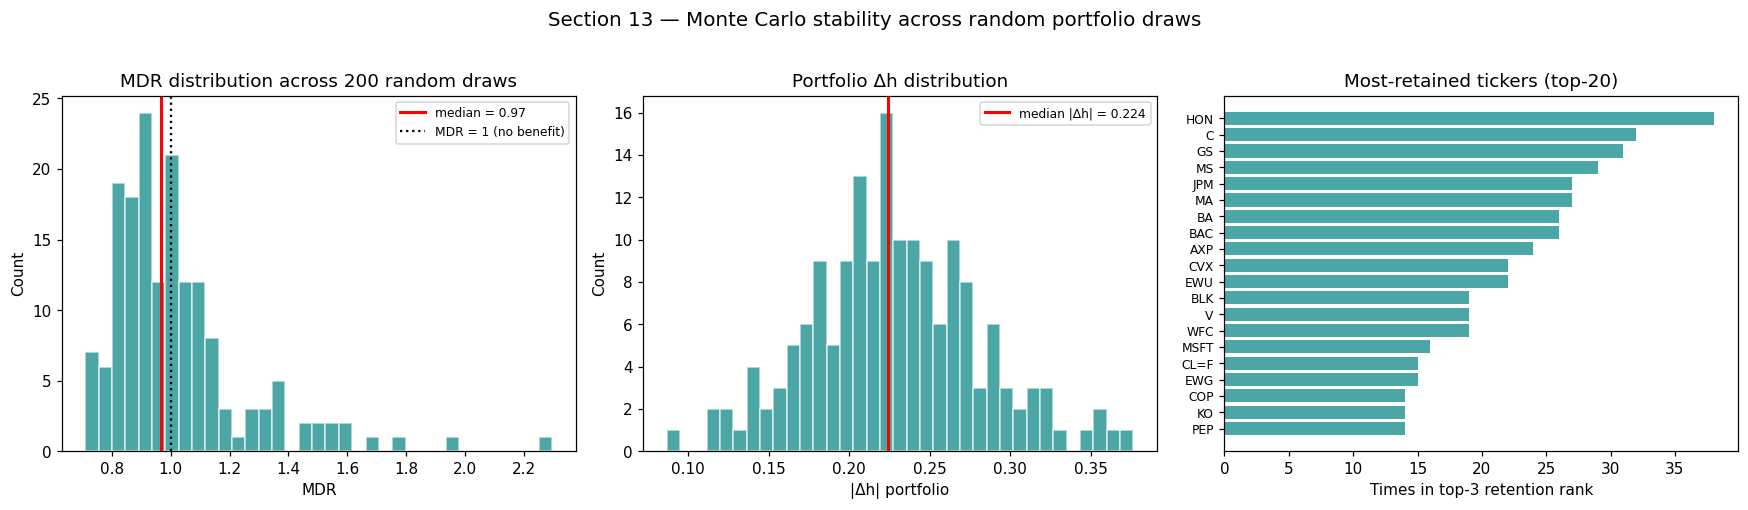


MDR across 200 draws:
  median = 0.967,  IQR = [0.877, 1.104]
  fraction MDR > 1: 36.0%
  fraction MDR > 1.5: 4.5%

Portfolio |Δh| across draws:
  median = 0.224,  IQR = [0.196, 0.262]


In [5]:
# ── Section 13: Monte Carlo Stability ───────────────────────────────────────

N_DRAWS   = 200
DRAW_SIZE = 7
MIN_DAYS  = 500
rng_mc    = np.random.default_rng(2024)

mc_scales  = lambda nn: np.unique(np.geomspace(16, max(20, nn//8), 12).astype(int))
mc_s_fixed = lambda nn: np.unique(np.geomspace(16, max(20, nn//8), 6).astype(int))

mc_MDRs       = []
mc_widths_p   = []
mc_top3_count = {t: 0 for t in available_tickers}
mc_draw_info  = []

print(f"Running {N_DRAWS} random {DRAW_SIZE}-asset draws…")
for draw_i in range(N_DRAWS):
    if (draw_i + 1) % 50 == 0:
        print(f"  draw {draw_i+1}/{N_DRAWS}")

    draw_tickers = list(rng_mc.choice(available_tickers, size=DRAW_SIZE, replace=False))

    try:
        pdf = pd.DataFrame({t: all_individual_prices[t] for t in draw_tickers}).dropna()
    except Exception:
        continue
    if len(pdf) < MIN_DAYS:
        continue

    d_returns = {t: np.diff(np.log(pdf[t].values)) for t in draw_tickers}
    nn = len(pdf) - 1

    ww    = np.ones(DRAW_SIZE) / DRAW_SIZE
    p_ret = sum(ww[i] * d_returns[t] for i, t in enumerate(draw_tickers))

    sc = mc_scales(nn)
    d_spec = {}
    for t in draw_tickers:
        _, hq_d = mfdfa(d_returns[t], q_list, sc)
        d_spec[t] = hq_d[0] - hq_d[-1]

    _, hq_pd = mfdfa(p_ret, q_list, sc)
    w_pd = hq_pd[0] - hq_pd[-1]

    naive_w = sum(ww[i] * d_spec[t] for i, t in enumerate(draw_tickers))
    mdr_d   = naive_w / w_pd if abs(w_pd) > 1e-12 else np.nan

    mc_MDRs.append(mdr_d)
    mc_widths_p.append(w_pd)

    # Retention ranking
    sf = mc_s_fixed(nn)
    d_vol   = {t: np.abs(d_returns[t]) for t in draw_tickers}
    d_vol_p = np.abs(p_ret)
    ret_rank = []
    for t in draw_tickers:
        rhos = []
        for s in sf:
            if len(d_vol[t]) >= s * 4:
                rhos.append(dcca_rho(d_vol[t], d_vol_p, s))
        ret_rank.append((t, np.mean(rhos) if rhos else np.nan))
    ret_rank.sort(key=lambda r: -(r[1] if np.isfinite(r[1]) else -999))
    for rank_pos, (t, _) in enumerate(ret_rank[:3]):
        mc_top3_count[t] += 1

    mc_draw_info.append((draw_i, draw_tickers, nn, mdr_d, w_pd))

mc_MDRs     = np.array(mc_MDRs)
mc_widths_p = np.array(mc_widths_p)
n_valid = len(mc_MDRs)
print(f"Completed {n_valid} valid draws (of {N_DRAWS} attempted).")

# ─── Plots ───
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ax = axes[0]
v = mc_MDRs[np.isfinite(mc_MDRs)]
ax.hist(v, bins=35, alpha=0.7, color='teal', edgecolor='white')
ax.axvline(np.nanmedian(v), color='red', lw=2, label=f'median = {np.nanmedian(v):.2f}')
ax.axvline(1.0, color='k', ls=':', lw=1.5, label='MDR = 1 (no benefit)')
ax.set_xlabel('MDR'); ax.set_ylabel('Count')
ax.set_title(f'MDR distribution across {n_valid} random draws')
ax.legend(fontsize=8)

ax = axes[1]
ax.hist(np.abs(mc_widths_p), bins=35, alpha=0.7, color='teal', edgecolor='white')
ax.axvline(np.nanmedian(np.abs(mc_widths_p)), color='red', lw=2,
           label=f'median |Δh| = {np.nanmedian(np.abs(mc_widths_p)):.3f}')
ax.set_xlabel('|Δh| portfolio'); ax.set_ylabel('Count')
ax.set_title('Portfolio Δh distribution')
ax.legend(fontsize=8)

ax = axes[2]
top3 = {t: c for t, c in mc_top3_count.items() if c > 0}
top3_sorted = sorted(top3.items(), key=lambda x: -x[1])[:20]
tnames  = [t for t, _ in top3_sorted]
tcounts = [c for _, c in top3_sorted]
ax.barh(range(len(tnames)), tcounts, color='teal', alpha=0.7)
ax.set_yticks(range(len(tnames))); ax.set_yticklabels(tnames, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('Times in top-3 retention rank'); ax.set_title('Most-retained tickers (top-20)')

plt.suptitle('Section 13 — Monte Carlo stability across random portfolio draws', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

print(f"\nMDR across {n_valid} draws:")
print(f"  median = {np.nanmedian(mc_MDRs):.3f},  IQR = [{np.nanpercentile(v,25):.3f}, {np.nanpercentile(v,75):.3f}]")
print(f"  fraction MDR > 1: {np.nanmean(mc_MDRs > 1):.1%}")
print(f"  fraction MDR > 1.5: {np.nanmean(mc_MDRs > 1.5):.1%}")
print(f"\nPortfolio |Δh| across draws:")
print(f"  median = {np.nanmedian(np.abs(mc_widths_p)):.3f},  IQR = [{np.nanpercentile(np.abs(mc_widths_p),25):.3f}, {np.nanpercentile(np.abs(mc_widths_p),75):.3f}]")


## 14. BTC / Equity Calendar Alignment — Sensitivity Analysis

BTC trades 365 d/yr; equities ~252. The current inner-join drops all weekends/holidays,
truncating the sample to BTC's start date (Sep 2014) and losing ~4.7 years of equity data.

We compare three modes:

| Mode | Description |
|------|-------------|
| A (current) | 7 assets incl. BTC, inner-join → ~2900 days (2014–2026) |
| B (equity-only) | 6 assets excl. BTC, inner-join → ~3800+ days (2010–2026) |
| C (matched dates) | 6 assets excl. BTC, restricted to Mode A dates |

- **A vs C** → effect of **adding BTC** to the portfolio
- **C vs B** → effect of **date truncation** caused by BTC's late start


                                     Mode A       Mode B       Mode C   A−C effect   C−B effect
                               (+BTC, 2014+) (−BTC, 2010+) (−BTC, 2014+)    (add BTC) (date trunc)
--------------------------------------------------------------------------------------------
N (days)                               2904         4088         2903                          
Portfolio |Δh|                       0.1805       0.1613       0.1363      +0.0443      -0.0251
MDR                                   1.356        1.251        1.750       -0.393       +0.499

Retention rankings:
  Mode A (+BTC, 2014–2026): JPM > EWJ > XOM > AAPL > JNJ > BTC-USD > GC=F
  Mode B (−BTC, 2010–2026): JPM > XOM > EWJ > JNJ > AAPL > GC=F
  Mode C (−BTC, 2014–2026): JPM > XOM > EWJ > AAPL > JNJ > GC=F


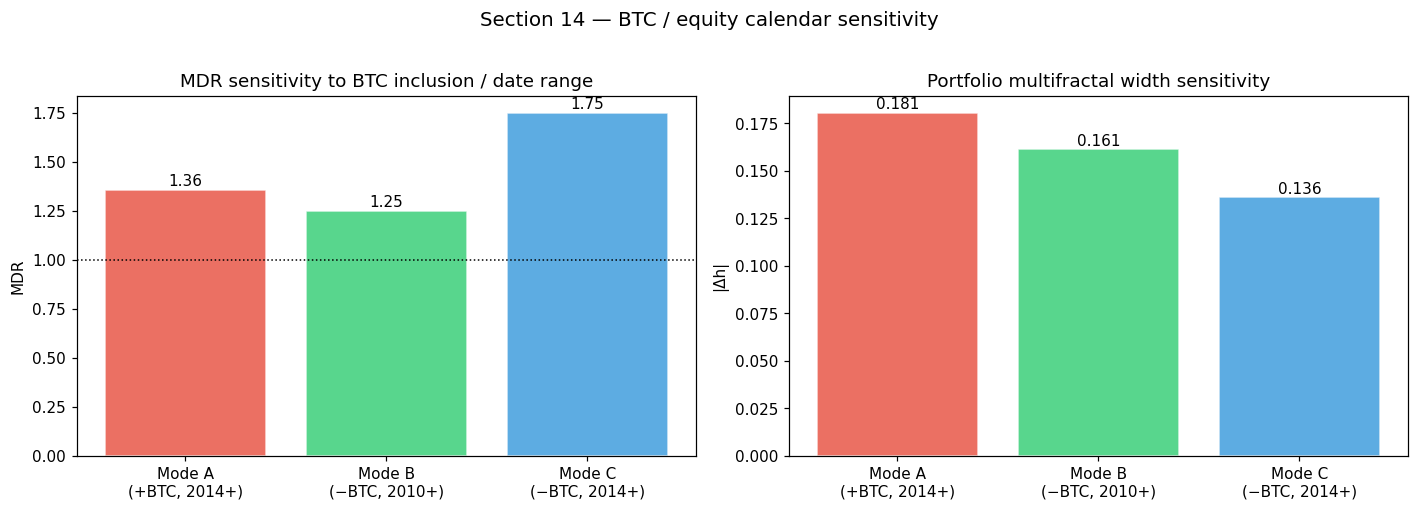


Conclusion: if A vs C differences are small, BTC calendar is not driving results.
If C vs B differences are large, the ~4-year date truncation matters more than BTC's calendar.


In [6]:
# ── Section 14: BTC / Equity Calendar Sensitivity ───────────────────────────

PORTFOLIO_EQ = [t for t in PORTFOLIO if t not in ("BTC-USD", "ETH-USD")]

# Mode A: current (with BTC) — already computed above
mode_a_N = N

# Mode B: equity-only, full date range
price_eq = get_prices(PORTFOLIO_EQ)
ret_eq   = {t: np.diff(np.log(price_eq[t].values)) for t in PORTFOLIO_EQ}
dates_eq = price_eq.index[1:]
ww_eq    = np.ones(len(PORTFOLIO_EQ)) / len(PORTFOLIO_EQ)
port_eq  = sum(ww_eq[i] * ret_eq[t] for i, t in enumerate(PORTFOLIO_EQ))

# Mode C: equity-only, restricted to Mode A date range
start_a = dates[0]
price_eq_c = price_eq.loc[price_eq.index >= start_a]
ret_eq_c   = {t: np.diff(np.log(price_eq_c[t].values)) for t in PORTFOLIO_EQ}
dates_eq_c = price_eq_c.index[1:]
port_eq_c  = sum(ww_eq[i] * ret_eq_c[t] for i, t in enumerate(PORTFOLIO_EQ))

def run_mode(p_ret, comp_returns, tickers, ww, nn):
    sc = np.unique(np.geomspace(16, max(20, nn//8), 14).astype(int))
    _, hq_p = mfdfa(p_ret, q_list, sc)
    w_p = hq_p[0] - hq_p[-1]
    comp_w = {}
    for t in tickers:
        _, hq_c = mfdfa(comp_returns[t], q_list, sc)
        comp_w[t] = hq_c[0] - hq_c[-1]
    naive = sum(ww[i] * comp_w[t] for i, t in enumerate(tickers))
    mdr_val = naive / w_p if abs(w_p) > 1e-12 else np.nan
    sf = np.unique(np.geomspace(16, max(20, nn//8), 8).astype(int))
    v  = {t: np.abs(comp_returns[t]) for t in tickers}
    vp = np.abs(p_ret)
    ret_rank = []
    for t in tickers:
        rhos = [dcca_rho(v[t], vp, s) for s in sf]
        ret_rank.append((t, np.mean(rhos)))
    ret_rank.sort(key=lambda r: -r[1])
    return w_p, mdr_val, ret_rank

wA, mdrA, rrA = run_mode(port_ret, returns, PORTFOLIO, weights, mode_a_N)
wB, mdrB, rrB = run_mode(port_eq, ret_eq, PORTFOLIO_EQ, ww_eq, len(dates_eq))
wC, mdrC, rrC = run_mode(port_eq_c, ret_eq_c, PORTFOLIO_EQ, ww_eq, len(dates_eq_c))

# ─── Comparison table ───
print(f"{'':30s} {'Mode A':>12s} {'Mode B':>12s} {'Mode C':>12s} {'A−C effect':>12s} {'C−B effect':>12s}")
print(f"{'':30s} {'(+BTC, 2014+)':>12s} {'(−BTC, 2010+)':>12s} {'(−BTC, 2014+)':>12s} {'(add BTC)':>12s} {'(date trunc)':>12s}")
print("-" * 92)
print(f"{'N (days)':30s} {mode_a_N:12d} {len(dates_eq):12d} {len(dates_eq_c):12d} {'':12s} {'':12s}")
print(f"{'Portfolio |Δh|':30s} {abs(wA):12.4f} {abs(wB):12.4f} {abs(wC):12.4f} {abs(wA)-abs(wC):+12.4f} {abs(wC)-abs(wB):+12.4f}")
print(f"{'MDR':30s} {mdrA:12.3f} {mdrB:12.3f} {mdrC:12.3f} {mdrA-mdrC:+12.3f} {mdrC-mdrB:+12.3f}")

print(f"\nRetention rankings:")
print(f"  Mode A (+BTC, 2014–2026): {' > '.join(t for t, _ in rrA)}")
print(f"  Mode B (−BTC, 2010–2026): {' > '.join(t for t, _ in rrB)}")
print(f"  Mode C (−BTC, 2014–2026): {' > '.join(t for t, _ in rrC)}")

# ─── Visual comparison ───
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
labels = ['Mode A\n(+BTC, 2014+)', 'Mode B\n(−BTC, 2010+)', 'Mode C\n(−BTC, 2014+)']
mdrs = [mdrA, mdrB, mdrC]
bars = ax.bar(labels, mdrs, color=['#e74c3c', '#2ecc71', '#3498db'], alpha=0.8, edgecolor='white')
ax.axhline(1, color='k', ls=':', lw=1)
ax.set_ylabel('MDR'); ax.set_title('MDR sensitivity to BTC inclusion / date range')
for b, v in zip(bars, mdrs):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.2f}', ha='center', fontsize=10)

ax = axes[1]
widths_cmp = [abs(wA), abs(wB), abs(wC)]
bars2 = ax.bar(labels, widths_cmp, color=['#e74c3c', '#2ecc71', '#3498db'], alpha=0.8, edgecolor='white')
ax.set_ylabel('|Δh|'); ax.set_title('Portfolio multifractal width sensitivity')
for b, v in zip(bars2, widths_cmp):
    ax.text(b.get_x() + b.get_width()/2, v + 0.002, f'{v:.3f}', ha='center', fontsize=10)

plt.suptitle('Section 14 — BTC / equity calendar sensitivity', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

print("\nConclusion: if A vs C differences are small, BTC calendar is not driving results.")
print("If C vs B differences are large, the ~4-year date truncation matters more than BTC's calendar.")


## 15. MF-DCCA vs. Linear Rolling-Correlation Retention — Dedicated Analysis

The divergence between ρ_DCCA retention ranking and linear rolling-correlation ranking
(observed in Section 4 of the original notebook) is the **most publishable single thread**.
This section gives it a full, dedicated decomposition:

- **15a.** Scale-by-scale scatter: where do the two metrics agree / diverge?
- **15b.** Regime-conditional retention: calm vs. crisis periods.
- **15c.** Which scales and which regimes drive the gap?


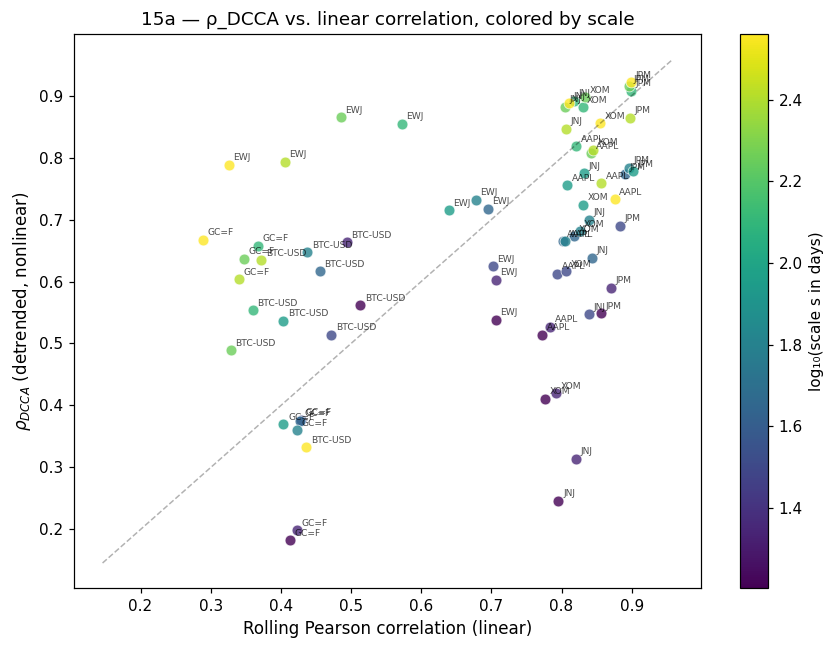

Points above the diagonal: MF-DCCA detects MORE co-movement than linear corr.
Points below: linear corr overstates co-movement (possibly driven by outliers).
Color gradient: if divergence grows with scale, the nonlinear cross-structure is
  a long-horizon phenomenon — exactly where portfolio risk models need it most.


In [7]:
# ── 15a: Scale-by-scale comparison ──────────────────────────────────────────

s_compare = np.unique(np.geomspace(16, N//8, 10).astype(int))

dcca_by_scale  = {s: {} for s in s_compare}
corr_by_scale  = {s: {} for s in s_compare}

for name in PORTFOLIO:
    for s in s_compare:
        dcca_by_scale[s][name] = dcca_rho(vol[name], vol_p, s)
        win = max(5, s)
        rv_comp = pd.Series(vol[name]).rolling(win).mean().values
        rv_port = pd.Series(vol_p).rolling(win).mean().values
        mask = ~(np.isnan(rv_comp) | np.isnan(rv_port))
        if mask.sum() > 10:
            corr_by_scale[s][name] = np.corrcoef(rv_comp[mask], rv_port[mask])[0, 1]
        else:
            corr_by_scale[s][name] = np.nan

# ─── Scatter plot ───
fig, ax = plt.subplots(figsize=(8, 6))
cmap = plt.cm.viridis
norm = plt.Normalize(np.log10(s_compare.min()), np.log10(s_compare.max()))

for s in s_compare:
    color = cmap(norm(np.log10(s)))
    for name in PORTFOLIO:
        x_val = corr_by_scale[s].get(name, np.nan)
        y_val = dcca_by_scale[s].get(name, np.nan)
        ax.scatter(x_val, y_val, color=color, s=50, alpha=0.8, edgecolor='white', lw=0.5)
        ax.annotate(name, (x_val, y_val), fontsize=6, alpha=0.7,
                    xytext=(3, 3), textcoords='offset points')

lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(lims, lims, 'k--', alpha=0.3, lw=1)
ax.set_xlabel('Rolling Pearson correlation (linear)', fontsize=11)
ax.set_ylabel(r'$\rho_{DCCA}$ (detrended, nonlinear)', fontsize=11)
ax.set_title('15a — ρ_DCCA vs. linear correlation, colored by scale')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('log₁₀(scale s in days)')
plt.tight_layout(); plt.show()

print("Points above the diagonal: MF-DCCA detects MORE co-movement than linear corr.")
print("Points below: linear corr overstates co-movement (possibly driven by outliers).")
print("Color gradient: if divergence grows with scale, the nonlinear cross-structure is")
print("  a long-horizon phenomenon — exactly where portfolio risk models need it most.")


               — Calm (Q1–Q3 vol) —          — Crisis (Q4 vol) —     
Ticker       Lin corr     ρ_DCCA    Gap     Lin corr     ρ_DCCA    Gap
--------------------------------------------------------------------------------
AAPL            0.408      0.320 -0.088        0.830      0.787 -0.043
JPM             0.510      0.430 -0.080        0.887      0.762 -0.125
XOM             0.400      0.258 -0.142        0.798      0.681 -0.116
JNJ             0.299      0.232 -0.067        0.922      0.668 -0.254
GC=F            0.186      0.113 -0.073        0.555      0.478 -0.077
BTC-USD         0.569      0.588 +0.019        0.310      0.559 +0.249
EWJ             0.268      0.355 +0.086        0.841      0.783 -0.057


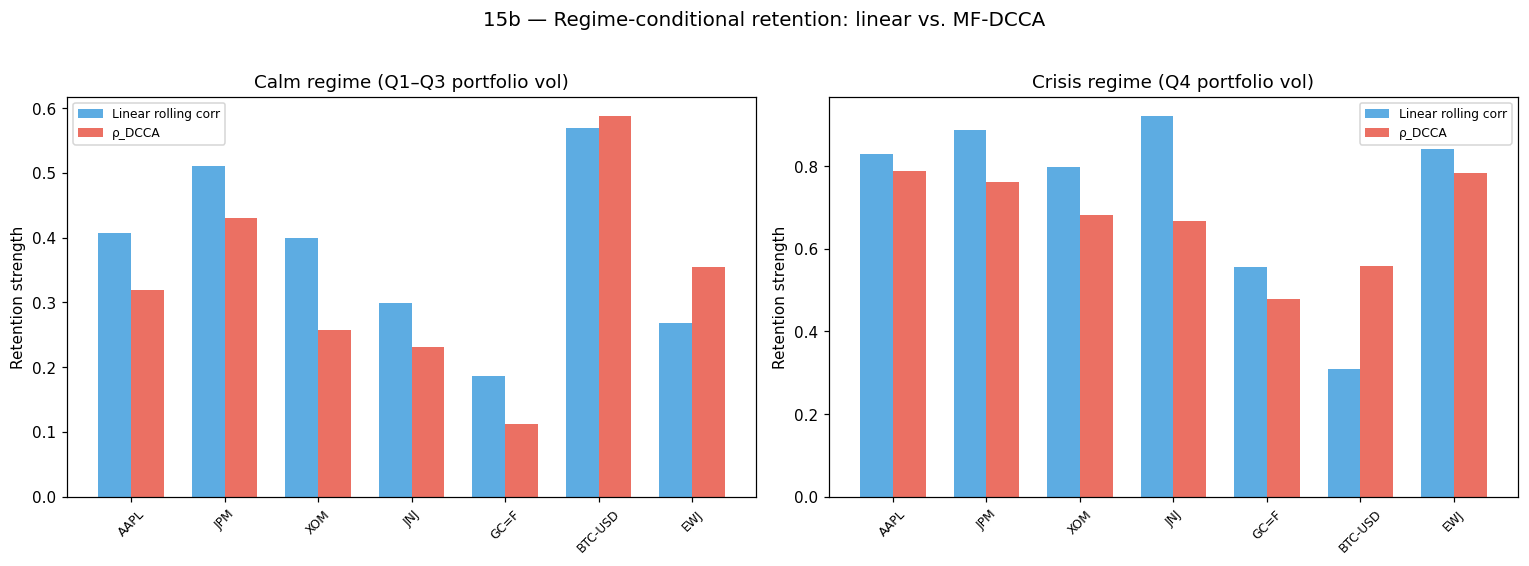


Key finding: if the DCCA–linear gap widens in crisis, the nonlinear cross-correlation
structure is specifically a stress-period phenomenon — exactly where risk models fail.


In [8]:
# ── 15b: Regime-conditional retention (calm vs. crisis) ────────────────────

roll_vol_proxy = pd.Series(vol_p).rolling(21).mean().values
vol_threshold  = np.nanpercentile(roll_vol_proxy, 75)

calm_mask   = (~np.isnan(roll_vol_proxy)) & (roll_vol_proxy <= vol_threshold)
crisis_mask = (~np.isnan(roll_vol_proxy)) & (roll_vol_proxy >  vol_threshold)

calm_idx   = np.where(calm_mask)[0]
crisis_idx = np.where(crisis_mask)[0]

def retention_corr(comp_vol_dict, port_vol, mask_idx, win=21):
    results = []
    for name in PORTFOLIO:
        rv_c = pd.Series(comp_vol_dict[name][mask_idx]).rolling(win).mean().values
        rv_p = pd.Series(port_vol[mask_idx]).rolling(win).mean().values
        m = ~(np.isnan(rv_c) | np.isnan(rv_p))
        c = np.corrcoef(rv_c[m], rv_p[m])[0, 1] if m.sum() > 20 else np.nan
        results.append((name, c))
    results.sort(key=lambda r: -r[1])
    return results

def retention_dcca(comp_vol_dict, port_vol, mask_idx, s_set):
    results = []
    for name in PORTFOLIO:
        sub_c = comp_vol_dict[name][mask_idx]
        sub_p = port_vol[mask_idx]
        if len(sub_c) < s_set[-1] * 3:
            results.append((name, np.nan))
            continue
        rhos = []
        for s in s_set:
            if len(sub_c) >= s * 4:
                rhos.append(dcca_rho(sub_c, sub_p, s))
        results.append((name, np.mean(rhos) if rhos else np.nan))
    results.sort(key=lambda r: -(r[1] if np.isfinite(r[1]) else -999))
    return results

vol_dict  = {name: np.abs(returns[name]) for name in PORTFOLIO}
sf_regime = np.unique(np.geomspace(16, min(200, N//16), 6).astype(int))

calm_lin    = retention_corr(vol_dict, vol_p, calm_idx)
crisis_lin  = retention_corr(vol_dict, vol_p, crisis_idx)
calm_dcca   = retention_dcca(vol_dict, vol_p, calm_idx, sf_regime)
crisis_dcca = retention_dcca(vol_dict, vol_p, crisis_idx, sf_regime)

# ─── Table ───
print(f"{'':9s}  {'— Calm (Q1–Q3 vol) —':^28s}  {'— Crisis (Q4 vol) —':^28s}")
print(f"{'Ticker':9s}  {'Lin corr':>10s} {'ρ_DCCA':>10s} {'Gap':>6s}   {'Lin corr':>10s} {'ρ_DCCA':>10s} {'Gap':>6s}")
print("-" * 80)
calm_lin_d    = {n: v for n, v in calm_lin}
calm_dcca_d   = {n: v for n, v in calm_dcca}
crisis_lin_d  = {n: v for n, v in crisis_lin}
crisis_dcca_d = {n: v for n, v in crisis_dcca}
for name in PORTFOLIO:
    cl = calm_lin_d.get(name, np.nan)
    cd = calm_dcca_d.get(name, np.nan)
    rl = crisis_lin_d.get(name, np.nan)
    rd = crisis_dcca_d.get(name, np.nan)
    cg = cd - cl if np.isfinite(cd) and np.isfinite(cl) else np.nan
    rg = rd - rl if np.isfinite(rd) and np.isfinite(rl) else np.nan
    print(f"{name:9s}  {cl:10.3f} {cd:10.3f} {cg:+6.3f}   {rl:10.3f} {rd:10.3f} {rg:+6.3f}")

# ─── Bar chart ───
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x_pos = np.arange(len(PORTFOLIO))
w_bar = 0.35

for ax_i, (title, lin_d, dcca_d) in enumerate([
    ("Calm regime (Q1–Q3 portfolio vol)", calm_lin_d, calm_dcca_d),
    ("Crisis regime (Q4 portfolio vol)", crisis_lin_d, crisis_dcca_d),
]):
    ax = axes[ax_i]
    lin_vals  = [lin_d.get(n, 0) for n in PORTFOLIO]
    dcca_vals = [dcca_d.get(n, 0) for n in PORTFOLIO]
    ax.bar(x_pos - w_bar/2, lin_vals, w_bar, label='Linear rolling corr', color='#3498db', alpha=0.8)
    ax.bar(x_pos + w_bar/2, dcca_vals, w_bar, label='ρ_DCCA', color='#e74c3c', alpha=0.8)
    ax.set_xticks(x_pos); ax.set_xticklabels(PORTFOLIO, rotation=45, fontsize=8)
    ax.set_ylabel('Retention strength')
    ax.set_title(title)
    ax.legend(fontsize=8); ax.axhline(0, color='k', lw=0.5)

plt.suptitle('15b — Regime-conditional retention: linear vs. MF-DCCA', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

print("\nKey finding: if the DCCA–linear gap widens in crisis, the nonlinear cross-correlation")
print("structure is specifically a stress-period phenomenon — exactly where risk models fail.")


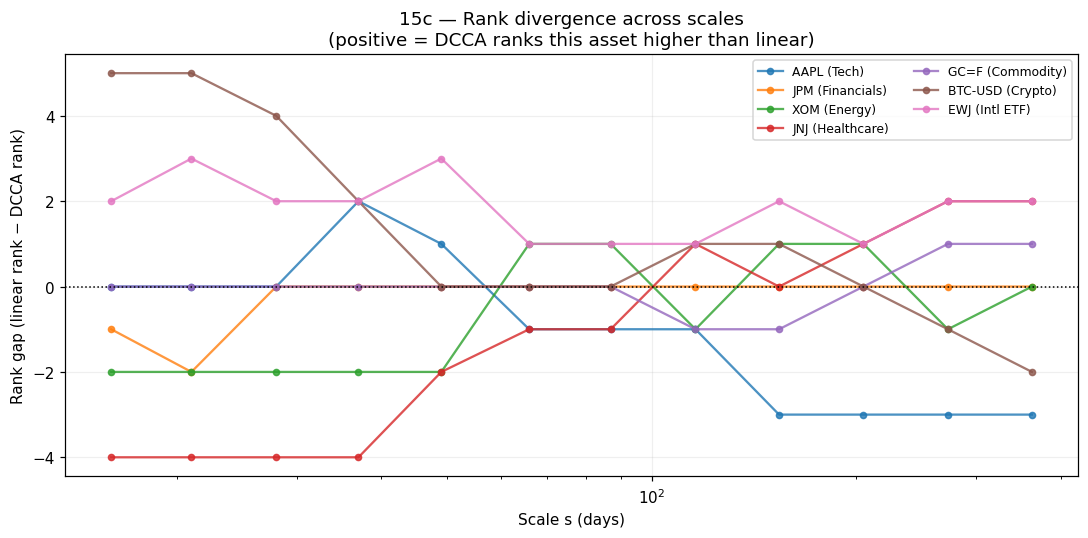

Scale-by-scale rank divergence:
Ticker       Short (s<50)      Medium    Long (s>200)
AAPL                +0.60       -1.50           -3.00
JPM                 -0.60       +0.00           +0.00
XOM                 -2.00       +0.50           +0.00
JNJ                 -3.60       -0.25           +1.67
GC=F                +0.00       -0.50           +0.67
BTC-USD             +3.20       +0.50           -1.00
EWJ                 +2.40       +1.25           +1.67

Assets with large positive long-scale gaps have cross-correlation structure that
linear methods miss entirely — these are the most dangerous blind spots for a
correlation-based risk model.


In [9]:
# ── 15c: Which scales drive the DCCA–linear gap? ───────────────────────────

all_scales_fine = np.unique(np.geomspace(16, N//8, 12).astype(int))

gap_by_scale = {name: [] for name in PORTFOLIO}
scale_list   = []

for s in all_scales_fine:
    dcca_vals = {name: dcca_rho(vol[name], vol_p, s) for name in PORTFOLIO}
    win = max(5, s)
    lin_vals = {}
    for name in PORTFOLIO:
        rv_c = pd.Series(vol[name]).rolling(win).mean().values
        rv_p = pd.Series(vol_p).rolling(win).mean().values
        m = ~(np.isnan(rv_c) | np.isnan(rv_p))
        lin_vals[name] = np.corrcoef(rv_c[m], rv_p[m])[0, 1] if m.sum() > 10 else np.nan

    dcca_rank = sorted(PORTFOLIO, key=lambda n: -dcca_vals[n])
    lin_rank  = sorted(PORTFOLIO, key=lambda n: -(lin_vals[n] if np.isfinite(lin_vals[n]) else -999))

    dcca_r = {n: i for i, n in enumerate(dcca_rank)}
    lin_r  = {n: i for i, n in enumerate(lin_rank)}

    for name in PORTFOLIO:
        gap_by_scale[name].append(lin_r[name] - dcca_r[name])

    scale_list.append(s)

# ─── Plot ───
fig, ax = plt.subplots(figsize=(10, 5))
for name in PORTFOLIO:
    ax.plot(scale_list, gap_by_scale[name], 'o-', label=f'{name} ({SECTOR[name]})', alpha=0.8, ms=4)
ax.axhline(0, color='k', lw=1, ls=':')
ax.set_xscale('log')
ax.set_xlabel('Scale s (days)'); ax.set_ylabel('Rank gap (linear rank − DCCA rank)')
ax.set_title('15c — Rank divergence across scales\n(positive = DCCA ranks this asset higher than linear)')
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

print("Scale-by-scale rank divergence:")
print(f"{'Ticker':9s}  {'Short (s<50)':>14s}  {'Medium':>10s}  {'Long (s>200)':>14s}")
for name in PORTFOLIO:
    gaps = np.array(gap_by_scale[name])
    scales_arr = np.array(scale_list)
    short_g = np.mean(gaps[scales_arr < 50]) if (scales_arr < 50).sum() > 0 else np.nan
    mid_g   = np.mean(gaps[(scales_arr >= 50) & (scales_arr <= 200)]) if ((scales_arr >= 50) & (scales_arr <= 200)).sum() > 0 else np.nan
    long_g  = np.mean(gaps[scales_arr > 200]) if (scales_arr > 200).sum() > 0 else np.nan
    print(f"{name:9s}  {short_g:+14.2f}  {mid_g:+10.2f}  {long_g:+14.2f}")

print("\nAssets with large positive long-scale gaps have cross-correlation structure that")
print("linear methods miss entirely — these are the most dangerous blind spots for a")
print("correlation-based risk model.")


## 16. Rolling MF-DCCA Event Study — Named Stress Episodes

Ties the rolling MF-DCCA panel (Section 6 of the original notebook) to real, named stress
episodes with a formal event-study framework: z-scores against a ±6-month baseline,
applied to a panel-average ρ̄_DCCA across **all** pairwise combinations in the portfolio.

| Event | Window |
|-------|--------|
| Fed taper tantrum | 2013-05-22 → 2013-09-05 |
| China devaluation / VIX spike | 2015-08-10 → 2015-08-25 |
| Volmageddon (XIV blow-up) | 2018-02-02 → 2018-02-12 |
| US-China trade war escalation | 2018-10-01 → 2018-12-24 |
| COVID-19 crash | 2020-02-19 → 2020-03-23 |
| Russia-Ukraine invasion | 2022-02-24 → 2022-03-15 |
| FTX collapse | 2022-11-06 → 2022-11-14 |
| SVB / banking stress | 2023-03-08 → 2023-03-20 |


Computing rolling ρ_DCCA for 21 pairs (window=750d, step=21d)…


Rolling panel computed: 103 windows, 95th %ile = 0.3883


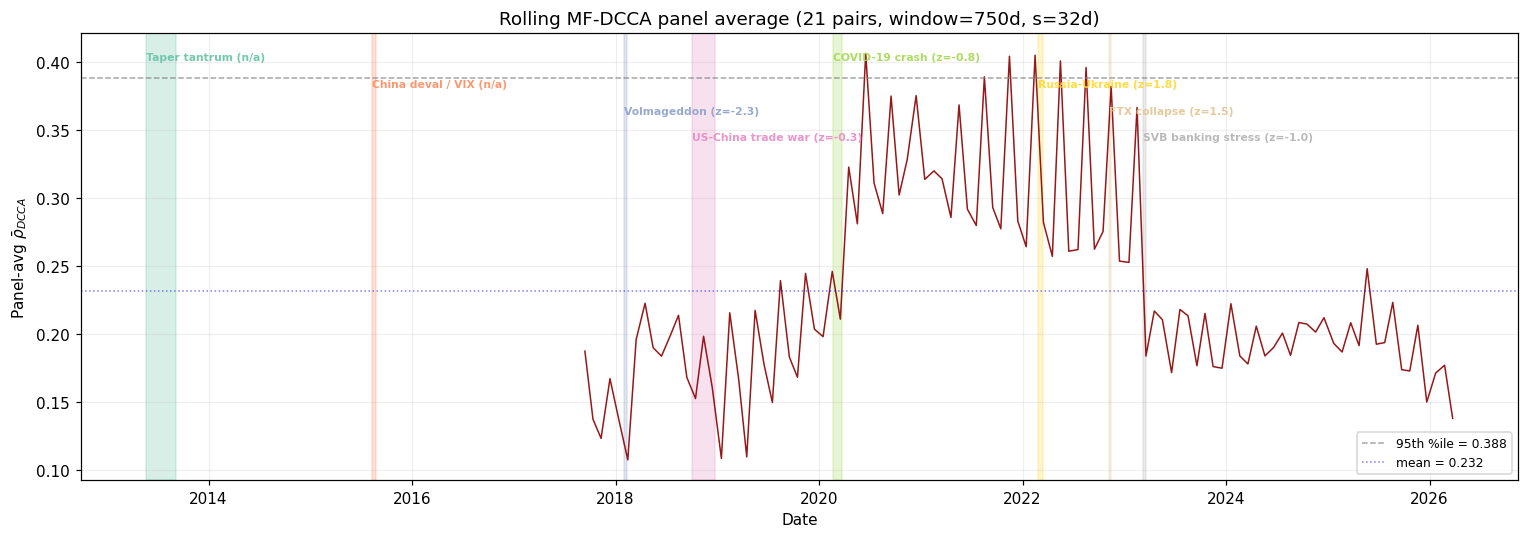


Event                     Window                      ρ̄_event    z-score    peak ρ̄  > 95%ile?
-----------------------------------------------------------------------------------------------
Taper tantrum             2013-05-22→2013-09-05           – out-of-range          –         no
China deval / VIX         2015-08-10→2015-08-25           – out-of-range          –         no
Volmageddon               2018-02-02→2018-02-12      0.1074      -2.26     0.1074         no
US-China trade war        2018-10-01→2018-12-24      0.1705      -0.28     0.1983         no
COVID-19 crash            2020-02-19→2020-03-23      0.2108      -0.80     0.2108         no
Russia-Ukraine            2022-02-24→2022-03-15      0.4050      +1.78     0.4050        YES
FTX collapse              2022-11-06→2022-11-14      0.3819      +1.51     0.3819         no
SVB banking stress        2023-03-08→2023-03-20      0.1838      -1.04     0.1838         no

Panel-avg ρ̄_DCCA 95th percentile (full sample): 0.3883
Ev

In [10]:
# ── Section 16: Rolling MF-DCCA Formal Event Study ─────────────────────────

EVENTS = [
    ("Taper tantrum",        "2013-05-22", "2013-09-05"),
    ("China deval / VIX",    "2015-08-10", "2015-08-25"),
    ("Volmageddon",          "2018-02-02", "2018-02-12"),
    ("US-China trade war",   "2018-10-01", "2018-12-24"),
    ("COVID-19 crash",       "2020-02-19", "2020-03-23"),
    ("Russia-Ukraine",       "2022-02-24", "2022-03-15"),
    ("FTX collapse",         "2022-11-06", "2022-11-14"),
    ("SVB banking stress",   "2023-03-08", "2023-03-20"),
]

# ─── Compute rolling panel-average ρ̄_DCCA ───
WINDOW_EV, STEP_EV, S_EV = 750, 21, 32
pairs_ev = list(combinations(PORTFOLIO, 2))

roll_dates_ev  = []
roll_rho_panel = []

print(f"Computing rolling ρ_DCCA for {len(pairs_ev)} pairs (window={WINDOW_EV}d, step={STEP_EV}d)…")
for end in range(WINDOW_EV, N, STEP_EV):
    start = end - WINDOW_EV
    rhos = []
    for a, b in pairs_ev:
        try:
            rho = dcca_rho(returns[a][start:end], returns[b][start:end], S_EV)
            if np.isfinite(rho):
                rhos.append(rho)
        except Exception:
            pass
    roll_rho_panel.append(np.mean(rhos) if rhos else np.nan)
    roll_dates_ev.append(dates[end])

roll_dates_ev  = pd.DatetimeIndex(roll_dates_ev)
roll_rho_panel = np.array(roll_rho_panel)

p95 = np.nanpercentile(roll_rho_panel, 95)
print(f"Rolling panel computed: {len(roll_rho_panel)} windows, 95th %ile = {p95:.4f}")

# ─── Event-study z-scores ───
event_results = []
BASELINE_DAYS = 126

for ev_name, ev_start, ev_end in EVENTS:
    es = pd.Timestamp(ev_start)
    ee = pd.Timestamp(ev_end)

    if es < roll_dates_ev[0] or ee > roll_dates_ev[-1]:
        event_results.append((ev_name, es, ee, np.nan, np.nan, np.nan, False))
        continue

    ev_mask = (roll_dates_ev >= es) & (roll_dates_ev <= ee)
    if ev_mask.sum() == 0:
        idx_near = np.argmin(np.abs(roll_dates_ev - es))
        ev_mask = np.zeros(len(roll_dates_ev), dtype=bool)
        ev_mask[idx_near] = True

    bl_start = es - pd.Timedelta(days=int(BASELINE_DAYS * 1.5))
    bl_end   = ee + pd.Timedelta(days=int(BASELINE_DAYS * 1.5))
    bl_mask  = (roll_dates_ev >= bl_start) & (roll_dates_ev <= bl_end) & ~ev_mask

    rho_event    = roll_rho_panel[ev_mask]
    rho_baseline = roll_rho_panel[bl_mask]

    rho_ev_mean = np.nanmean(rho_event)
    bl_mu       = np.nanmean(rho_baseline)
    bl_sigma    = np.nanstd(rho_baseline)

    z = (rho_ev_mean - bl_mu) / bl_sigma if bl_sigma > 1e-8 else np.nan
    exceeds_95 = rho_ev_mean > p95

    event_results.append((ev_name, es, ee, rho_ev_mean, z, np.nanmax(rho_event), exceeds_95))

# ─── Timeline plot ───
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(roll_dates_ev, roll_rho_panel, color='darkred', lw=1, alpha=0.9)
ax.axhline(p95, color='gray', ls='--', lw=1, alpha=0.7, label=f'95th %ile = {p95:.3f}')
ax.axhline(np.nanmean(roll_rho_panel), color='blue', ls=':', lw=1, alpha=0.5,
           label=f'mean = {np.nanmean(roll_rho_panel):.3f}')

colors_ev = plt.cm.Set2(np.linspace(0, 1, len(EVENTS)))
for i, (ev_name, es, ee, rho_ev, z, peak, exc) in enumerate(event_results):
    ax.axvspan(es, ee, alpha=0.25, color=colors_ev[i])
    y_pos = ax.get_ylim()[1] - (i % 4 + 1) * (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.06
    z_str = f'z={z:.1f}' if np.isfinite(z) else 'n/a'
    ax.annotate(f'{ev_name} ({z_str})', xy=(es, y_pos),
                fontsize=7, color=colors_ev[i], fontweight='bold', alpha=0.9)

ax.set_xlabel('Date'); ax.set_ylabel(r'Panel-avg $\bar{{\rho}}_{{DCCA}}$')
ax.set_title(f'Rolling MF-DCCA panel average ({len(pairs_ev)} pairs, window={WINDOW_EV}d, s={S_EV}d)')
ax.legend(loc='lower right', fontsize=8)
ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

# ─── Event study table ───
print(f"\n{'Event':25s} {'Window':25s} {'ρ̄_event':>10s} {'z-score':>10s} {'peak ρ̄':>10s} {'> 95%ile?':>10s}")
print("-" * 95)
for ev_name, es, ee, rho_ev, z, peak, exc in event_results:
    z_s   = f'{z:+.2f}' if np.isfinite(z) else 'out-of-range'
    rho_s = f'{rho_ev:.4f}' if np.isfinite(rho_ev) else '–'
    pk_s  = f'{peak:.4f}' if np.isfinite(peak) else '–'
    print(f"{ev_name:25s} {str(es.date()):>10s}→{str(ee.date()):>10s}  {rho_s:>10s} {z_s:>10s} {pk_s:>10s} {'YES' if exc else 'no':>10s}")

print(f"\nPanel-avg ρ̄_DCCA 95th percentile (full sample): {p95:.4f}")
print("Events with z > 2 and exceeding 95th %ile are formal stress-regime signals.")
